# Project 06: Quiz Management System

## Objective
To develop a quiz management system using Python Object-Oriented Programming (OOP).

## Features
- Load questions from a file
- Conduct a quiz
- Calculate the score
- Save quiz results

## Concepts Used
- Classes and Objects
- Constructors (__init__)
- Instance attributes and methods
- File handling
- JSON


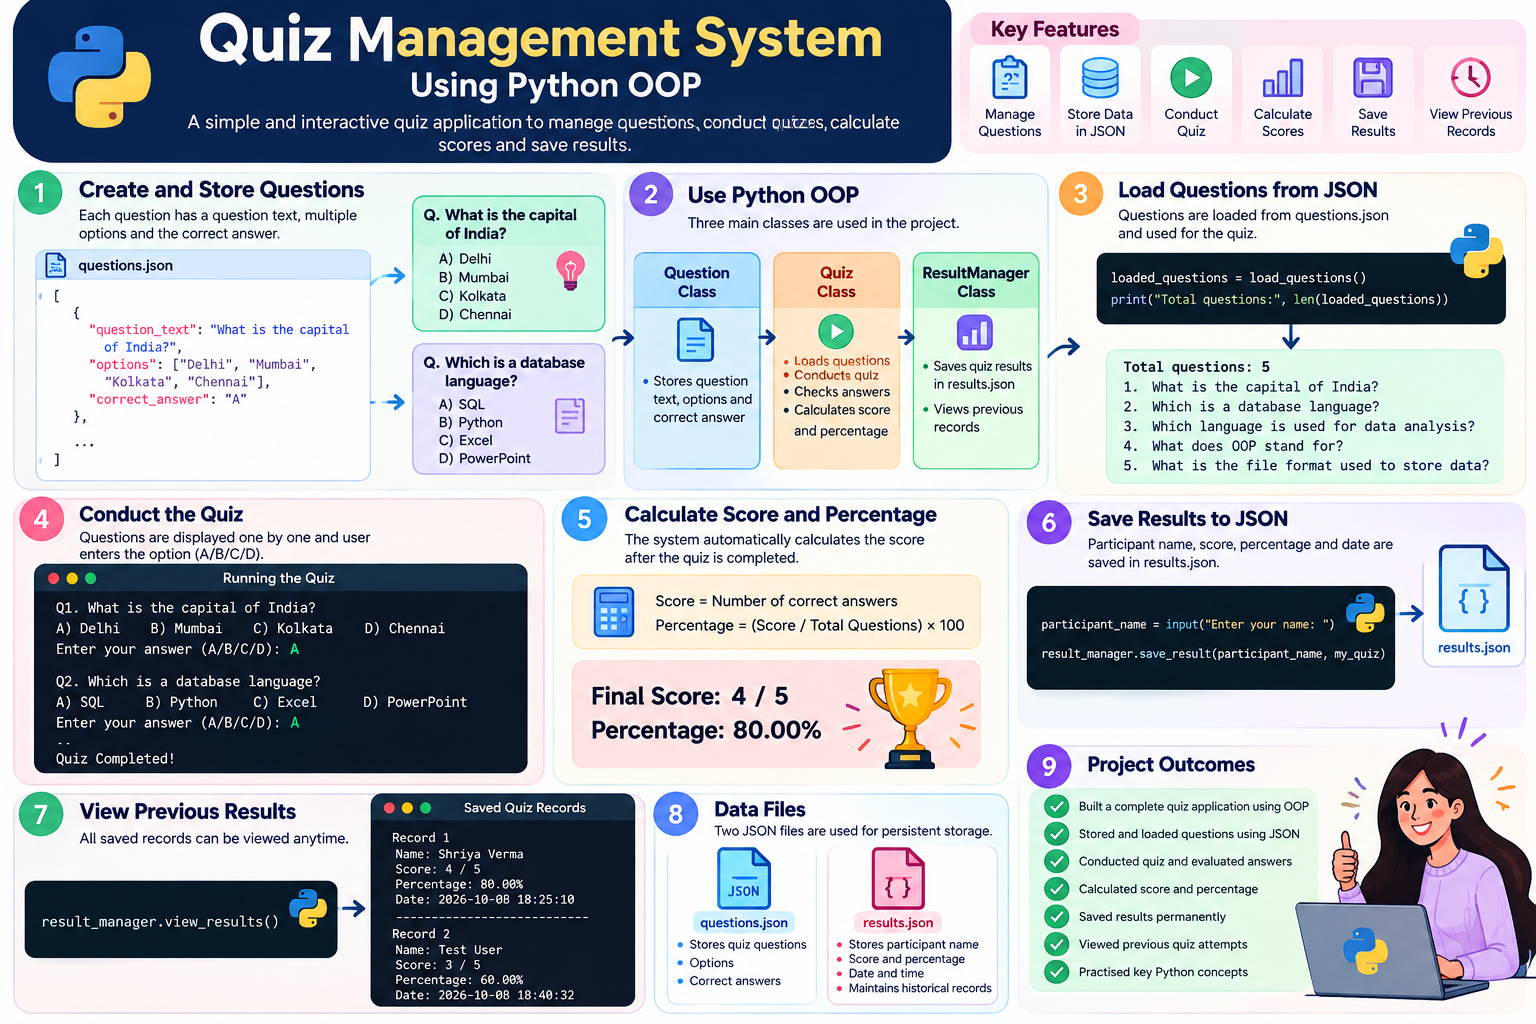

In [1]:
class Question:
    def __init__(self, question_text, options, correct_answer):
        self.question_text = question_text
        self.options = options
        self.correct_answer = correct_answer

In [12]:
q1 = Question(
    "What is the capital of India?",
    ["Delhi", "Mumbai", "Kolkata", "Chennai"],
    "Delhi"
)

print(q1.question_text)
print(q1.options)
print(q1.correct_answer)

What is the capital of India?
['Delhi', 'Mumbai', 'Kolkata', 'Chennai']
Delhi


In [11]:
class Question:
    def __init__(self, question_text, options, correct_answer):
        self.question_text = question_text
        self.options = options
        self.correct_answer = correct_answer

    def to_dict(self):
        return {
            "question_text": self.question_text,
            "options": self.options,
            "correct_answer": self.correct_answer
        }
        

In [13]:
questions = [
    q1,
    Question(
        "Which language are we using for this project?",
        ["Java", "Python", "C++", "HTML"],
        "Python"
    )
]

In [15]:
import json

In [16]:
with open("questions.json", "w") as file:
    json.dump(
        [question.to_dict() for question in questions],
        file,
        indent=4
    )

print("Questions saved successfully!")

Questions saved successfully!


In [17]:
def load_questions(filename="questions.json"):
    with open(filename, "r") as file:
        data = json.load(file)

    questions = []

    for item in data:
        question = Question(
            item["question_text"],
            item["options"],
            item["correct_answer"]
        )
        questions.append(question)

    return questions

In [18]:
loaded_questions = load_questions()

print("Total questions loaded:", len(loaded_questions))

for question in loaded_questions:
    print(question.question_text)

Total questions loaded: 2
What is the capital of India?
Which language are we using for this project?


In [33]:
class Quiz:
    def __init__(self, questions):
        self.questions = questions
        self.score = 0

    def conduct_quiz(self):
        self.score = 0

        for index, question in enumerate(self.questions, start=1):
            print(f"\nQuestion {index}: {question.question_text}")

            for number, option in enumerate(question.options, start=1):
                print(f"{number}. {option}")

            while True:
                answer = input(
                    f"Enter your answer (1-{len(question.options)}): "
                )

                if answer.isdigit():
                    answer_number = int(answer)

                    if 1 <= answer_number <= len(question.options):
                        break

                print("Invalid input. Please enter a valid option number.")

            selected_answer = question.options[answer_number - 1]

            if selected_answer.casefold() == question.correct_answer.casefold():
                print("Correct answer!")
                self.score += 1
            else:
                print(f"Incorrect! Correct answer: {question.correct_answer}")

        print("\nQuiz completed!")
        print(f"Your score: {self.score}/{len(self.questions)}")

    def calculate_percentage(self):
        if not self.questions:
            return 0

        return (self.score / len(self.questions)) * 100

In [20]:
from datetime import datetime

In [22]:
class ResultManager:
    def __init__(self, filename="results.json"):
        self.filename = filename

    def save_result(self, name, quiz):
        result = {
            "name": name,
            "score": quiz.score,
            "total_questions": len(quiz.questions),
            "percentage": quiz.calculate_percentage(),
            "date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        }

        try:
            with open(self.filename, "r") as file:
                results = json.load(file)
        except FileNotFoundError:
            results = []

        results.append(result)

        with open(self.filename, "w") as file:
            json.dump(results, file, indent=4)

        print("Quiz result saved successfully!")

In [24]:
class ResultManager:
    def __init__(self, filename="results.json"):
        self.filename = filename

    def save_result(self, name, quiz):
        result = {
            "name": name,
            "score": quiz.score,
            "total_questions": len(quiz.questions),
            "percentage": quiz.calculate_percentage(),
            "date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        }

        try:
            with open(self.filename, "r") as file:
                results = json.load(file)
        except FileNotFoundError:
            results = []

        results.append(result)

        with open(self.filename, "w") as file:
            json.dump(results, file, indent=4)

        print("Quiz result saved successfully!")

In [26]:
result_manager = ResultManager()

In [28]:
quiz_questions = load_questions()

my_quiz = Quiz(quiz_questions)

In [29]:
my_quiz.conduct_quiz()


Question 1: What is the capital of India?
1. Delhi
2. Mumbai
3. Kolkata
4. Chennai


Enter your answer (1-4):  1


Correct answer!

Question 2: Which language are we using for this project?
1. Java
2. Python
3. C++
4. HTML


Enter your answer (1-4):  2


Correct answer!

Quiz completed!
Your score: 2/2


In [30]:
participant_name = input("Enter your name: ")

result_manager.save_result(participant_name, my_quiz)

Enter your name:  Shriya Verma


Quiz result saved successfully!


In [31]:
with open("results.json", "r") as file:
    saved_results = json.load(file)

print(saved_results)

[{'name': 'Shriya Verma', 'score': 2, 'total_questions': 2, 'percentage': 100.0, 'date': '2026-10-10 00:26:41'}]


In [43]:
class ResultManager:
    def __init__(self, filename="results.json"):
        self.filename = filename

    def save_result(self, name, quiz):
        result = {
            "name": name,
            "score": quiz.score,
            "total_questions": len(quiz.questions),
            "percentage": quiz.calculate_percentage(),
            "date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        }

        try:
            with open(self.filename, "r") as file:
                results = json.load(file)
        except FileNotFoundError:
            results = []

        results.append(result)

        with open(self.filename, "w") as file:
            json.dump(results, file, indent=4)

        print("Quiz result saved successfully!")

    def view_results(self):
        try:
            with open(self.filename, "r") as file:
                results = json.load(file)
        except FileNotFoundError:
            print("No quiz records found yet.")
            return

        if not results:
            print("No quiz records found yet.")
            return

        for index, result in enumerate(results, start=1):
            print(f"\nRecord {index}")
            print("Name:", result["name"])
            print("Score:", f'{result["score"]}/{result["total_questions"]}')
            print("Percentage:", f'{result["percentage"]:.2f}%')
            print("Date:", result["date"])

In [34]:
def add_question(question_text, options, correct_answer):
    questions = load_questions()

    new_question = Question(
        question_text,
        options,
        correct_answer
    )

    questions.append(new_question)

    with open("questions.json", "w") as file:
        json.dump(
            [question.to_dict() for question in questions],
            file,
            indent=4
        )

    print("New question added successfully!")

In [35]:
add_question(
    "Which library is commonly used for data analysis in Python?",
    ["NumPy", "Pandas", "Matplotlib", "All of these"],
    "All of these"
)

New question added successfully!


In [36]:
loaded_questions = load_questions()

print("Total questions:", len(loaded_questions))

for index, question in enumerate(loaded_questions, start=1):
    print(f"{index}. {question.question_text}")

Total questions: 3
1. What is the capital of India?
2. Which language are we using for this project?
3. Which library is commonly used for data analysis in Python?


In [37]:
def add_question(question_text, options, correct_answer):
    question_text = question_text.strip()
    correct_answer = correct_answer.strip()

    if not question_text:
        print("Error: Question text cannot be empty.")
        return

    if len(options) < 2:
        print("Error: A question must have at least two options.")
        return

    options = [option.strip() for option in options]

    if any(not option for option in options):
        print("Error: Options cannot be empty.")
        return

    if len(set(option.casefold() for option in options)) != len(options):
        print("Error: Duplicate options are not allowed.")
        return

    if correct_answer.casefold() not in [option.casefold() for option in options]:
        print("Error: Correct answer must match one of the options.")
        return

    questions = load_questions()

    for question in questions:
        if question.question_text.casefold() == question_text.casefold():
            print("Error: This question already exists.")
            return

    new_question = Question(
        question_text,
        options,
        correct_answer
    )

    questions.append(new_question)

    with open("questions.json", "w") as file:
        json.dump(
            [question.to_dict() for question in questions],
            file,
            indent=4
        )

    print("New question added successfully!")

In [38]:
loaded_questions = load_questions()

print("Total questions:", len(loaded_questions))

for question in loaded_questions:
    print(question.question_text)

Total questions: 3
What is the capital of India?
Which language are we using for this project?
Which library is commonly used for data analysis in Python?


In [39]:
my_quiz = Quiz(loaded_questions)

my_quiz.conduct_quiz()


Question 1: What is the capital of India?
1. Delhi
2. Mumbai
3. Kolkata
4. Chennai


Enter your answer (1-4):  4


Incorrect! Correct answer: Delhi

Question 2: Which language are we using for this project?
1. Java
2. Python
3. C++
4. HTML


Enter your answer (1-4):  3


Incorrect! Correct answer: Python

Question 3: Which library is commonly used for data analysis in Python?
1. NumPy
2. Pandas
3. Matplotlib
4. All of these


Enter your answer (1-4):  4


Correct answer!

Quiz completed!
Your score: 1/3


In [40]:
percentage = my_quiz.calculate_percentage()

print("Final percentage:", percentage, "%")

Final percentage: 33.33333333333333 %


In [41]:
participant_name = input("Enter your name: ")

result_manager.save_result(participant_name, my_quiz)

Enter your name:  Shriya Verma


Quiz result saved successfully!


In [45]:
import json

class ResultManager:
    def __init__(self, filename="results.json"):
        self.filename = filename

    def save_result(self, name, quiz):
        result = {
            "name": name,
            "score": quiz.score,
            "total_questions": len(quiz.questions),
            "percentage": quiz.calculate_percentage(),
            "date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        }

        try:
            with open(self.filename, "r") as file:
                results = json.load(file)
        except FileNotFoundError:
            results = []

        results.append(result)

        with open(self.filename, "w") as file:
            json.dump(results, file, indent=4)

        print("Quiz result saved successfully!")

    def view_results(self):
        try:
            with open(self.filename, "r") as file:
                results = json.load(file)
        except FileNotFoundError:
            print("No quiz records found.")
            return

        if len(results) == 0:
            print("No quiz records found.")
            return

        for result in results:
            print("--------------------")
            print("Name:", result["name"])
            print("Score:", result["score"], "/", result["total_questions"])
            print("Percentage:", result["percentage"], "%")
            print("Date:", result["date"])


result_manager = ResultManager()
print("ResultManager updated successfully!")

ResultManager updated successfully!


In [46]:
result_manager.view_results()

--------------------
Name: Shriya Verma
Score: 2 / 2
Percentage: 100.0 %
Date: 2026-10-10 00:26:41
--------------------
Name: Shriya Verma
Score: 1 / 3
Percentage: 33.33333333333333 %
Date: 2026-10-10 00:55:42


In [47]:
loaded_questions = load_questions()

print("Total questions:", len(loaded_questions))

for question in loaded_questions:
    print(question.question_text)

Total questions: 3
What is the capital of India?
Which language are we using for this project?
Which library is commonly used for data analysis in Python?


In [48]:
my_quiz = Quiz(loaded_questions)
my_quiz.conduct_quiz()


Question 1: What is the capital of India?
1. Delhi
2. Mumbai
3. Kolkata
4. Chennai


Enter your answer (1-4):  1


Correct answer!

Question 2: Which language are we using for this project?
1. Java
2. Python
3. C++
4. HTML


Enter your answer (1-4):  2


Correct answer!

Question 3: Which library is commonly used for data analysis in Python?
1. NumPy
2. Pandas
3. Matplotlib
4. All of these


Enter your answer (1-4):  5


Invalid input. Please enter a valid option number.


Enter your answer (1-4):  3


Incorrect! Correct answer: All of these

Quiz completed!
Your score: 2/3


In [49]:
participant_name = input("Enter your name: ")
result_manager.save_result(participant_name, my_quiz)

Enter your name:  Mohit Sharma


Quiz result saved successfully!


In [50]:
result_manager.view_results()

--------------------
Name: Shriya Verma
Score: 2 / 2
Percentage: 100.0 %
Date: 2026-10-10 00:26:41
--------------------
Name: Shriya Verma
Score: 1 / 3
Percentage: 33.33333333333333 %
Date: 2026-10-10 00:55:42
--------------------
Name: Mohit Sharma
Score: 2 / 3
Percentage: 66.66666666666666 %
Date: 2026-10-10 01:07:54
